In [142]:
import torch
from torch import linalg, optim
import matplotlib.pyplot as plt

In [143]:
def my_muon(W, lr):
    lr_scale = max(1, W.shape[0] / W.shape[1]) ** 0.5
    return optim.Muon(
        [W], lr=lr / lr_scale,
        momentum=0.0, nesterov=False, weight_decay=0.0,
        ns_coefficients=(1.5, -0.5, 0.0), ns_steps=10,
        adjust_lr_fn="original",
    )

In [144]:
torch.manual_seed(123)

r = 8
L = torch.diag(torch.tensor([100.] + [1.] * (r - 1)))
Q, _ = linalg.qr(torch.randn(r, r))
M = Q @ L @ Q.T

def F(U):
    return 0.25 * linalg.matrix_norm(U @ U.T - M, ord='fro') ** 2

In [145]:
n_optimizers = 3
Xs = [torch.randn(r, r, requires_grad=True) for _ in range(n_optimizers)]
optimizers = [
    optim.SGD([Xs[0]], lr=0.005),
    optim.Adam([Xs[1]], lr=0.05),
    my_muon(Xs[2], lr=0.05)
]

losses = [[] for _ in range(n_optimizers)]
epochs = 1000
for _ in range(epochs):
    for X, opt, loss_list in zip(Xs, optimizers, losses):
        opt.zero_grad()
        loss = F(X)
        loss_list.append(loss.item())
        loss.backward()
        opt.step()

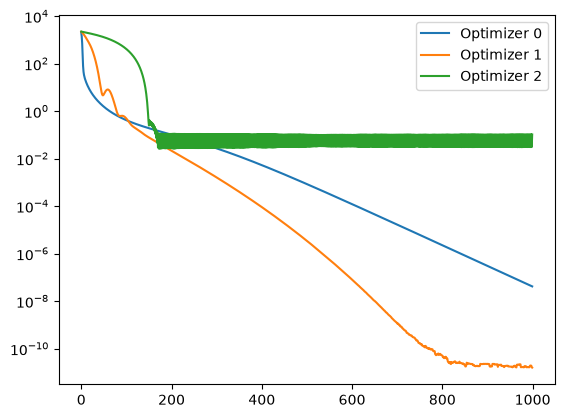

In [146]:
for i, loss_list in enumerate(losses):
    plt.plot(range(epochs), loss_list, label=f'Optimizer {i}')
plt.legend()
plt.yscale('log')
plt.show()